# GEOG 592 — Week 9 Homework
## Cartography with Matplotlib

In [2]:
# https://www.gbif.org/

import time
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt



species = ["Vulpes vulpes", "Urocyon cinereoargenteus"]
year = 2025

api = "https://api.gbif.org/v1"
records = []

for name in species:

    # 1. Find the GBIF taxon identifier for the scientific name.
    response = requests.get(
        f"{api}/species/match",
        params={"name": name, "strict": "true"},
        timeout=60
    )
    response.raise_for_status()
    match = response.json()

    if (
        match.get("matchType") != "EXACT"
        or match.get("rank") != "SPECIES"
    ):
        raise ValueError(f"Check the species name: {name}")

    taxon_key = match.get("acceptedUsageKey", match["usageKey"])

    # 2. Define which occurrence records to request.
    parameters = {
        "taxonKey": taxon_key,
        "country": "US",
        # "stateProvince": "North Carolina",
        "year": year,
        "basisOfRecord": "HUMAN_OBSERVATION",
        "occurrenceStatus": "PRESENT",
        "hasCoordinate": "true",
        "hasGeospatialIssue": "false",
        "limit": 300,
        "offset": 0
    }

    # 3. Retrieve successive pages of records.
    species_records = []

    while True:
        response = requests.get(
            f"{api}/occurrence/search",
            params=parameters,
            timeout=60
        )
        response.raise_for_status()
        page = response.json()

        # LIMIT THE NUMBER OF CASES (you can chage it but, the larger the number...the longer the wait)
        if page["count"] > 9000:
            raise ValueError(
                f"{name} has too many records for this example. "
                "Narrow the date range or use a GBIF bulk download."
            )

        for record in page["results"]:
            record["queried_species"] = name

        species_records.extend(page["results"])

        if page.get("endOfRecords") or not page["results"]:
            break

        parameters["offset"] += len(page["results"])
        time.sleep(0.2)

    records.extend(species_records)
    print(f"{name}: {len(species_records):,} records")


Vulpes vulpes: 6,204 records
Urocyon cinereoargenteus: 4,171 records


In [3]:
foxes = pd.DataFrame(records)
foxes = foxes[["queried_species", "decimalLongitude", "decimalLatitude"]] 
foxes.head()

,queried_species,decimalLongitude,decimalLatitude
0,Vulpes vulpes,-71.863675,44.461650
1,Vulpes vulpes,-77.285038,39.036542
2,Vulpes vulpes,-74.425279,40.458382
3,Vulpes vulpes,-77.252229,38.621250
4,Vulpes vulpes,-77.349752,38.937001


<Axes: >

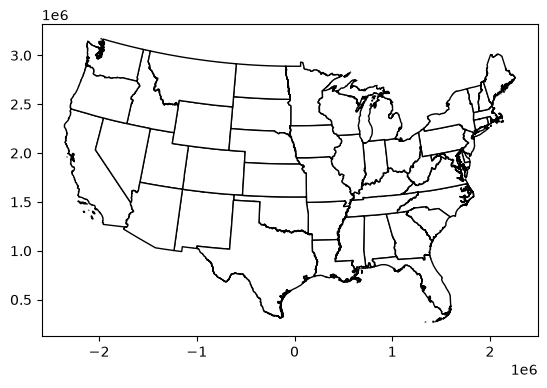

In [4]:
# getting the US census data

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 


### Code for county level data 

# counties = gpd.read_file(url_0+url_county)
# nc_counties = counties.loc[counties["STATEFP"] == "37"].copy()
# nc_counties.plot(edgecolor="black", facecolor="white")

## remove Alaska, Hawaii and those other islands which makes mapping difficult, but life much nicer.  
states = gpd.read_file(url_0+url_state)
contiguous_us = states.loc[
    ~states["STUSPS"].isin(["AK", "HI", "PR", "VI", "GU", "MP", "AS"])
]

contiguous_us = contiguous_us.to_crs(epsg=5070)
contiguous_us.plot(edgecolor="black", facecolor="white")



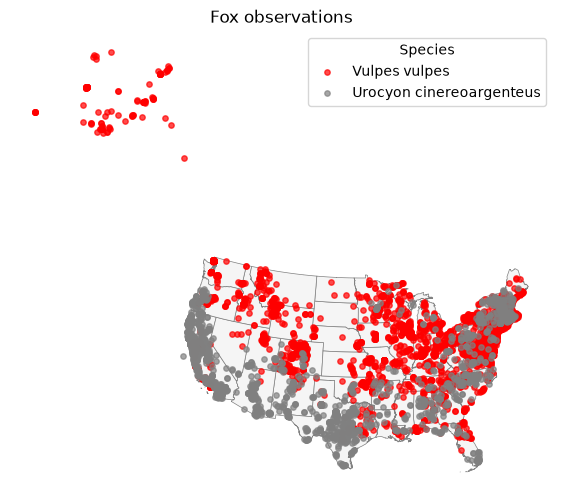

In [5]:

## make a gdp from the x and y data. 
fox_points = gpd.GeoDataFrame(
    foxes.copy(),
    geometry=gpd.points_from_xy( ## the method is calleed points_from_xy
        foxes["decimalLongitude"], # x
        foxes["decimalLatitude"] # y
        ),
    crs="EPSG:4326" # often the crs is in 4326 if it is a lat lon coordinate
    )

fox_points = fox_points.to_crs(epsg=5070)


fig, ax = plt.subplots(figsize=(12, 6))
contiguous_us.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="gray",
    linewidth=0.5
)

colors = {"Vulpes vulpes": "red", "Urocyon cinereoargenteus": "gray"}

for species, color in colors.items():
    fox_points.loc[
        fox_points["queried_species"] == species
    ].plot(
        ax=ax,
        color=color,
        markersize=15,
        alpha=0.7,
        label=species
    )

ax.set_title("Fox observations")
ax.legend(title="Species")
ax.set_axis_off()

plt.show()

In [6]:
# select points within contiguous states and keep the NAME of the state. 
points_by_state = gpd.sjoin(
    fox_points,
    contiguous_us[["NAME", "geometry"]],
    how="inner",
    predicate="within"
).drop(columns="index_right")

points_by_state.head()

,queried_species,decimalLongitude,decimalLatitude,geometry,NAME
0,Vulpes vulpes,-71.863675,44.461650,POINT (1895265.228 2627757.285),Vermont
1,Vulpes vulpes,-77.285038,39.036542,POINT (1594618.45 1936529.956),Virginia
2,Vulpes vulpes,-74.425279,40.458382,POINT (1798508.726 2143364.206),New Jersey
3,Vulpes vulpes,-77.252229,38.621250,POINT (1606500.955 1891435.963),Virginia
4,Vulpes vulpes,-77.349752,38.937001,POINT (1591351.049 1924503.287),Virginia


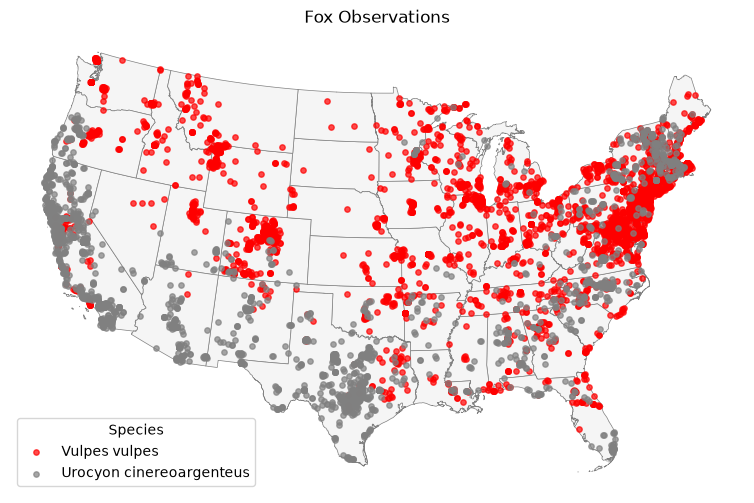

In [8]:
fig, ax = plt.subplots(figsize=(12, 6)) # creating the fig and ax objects using plt
contiguous_us.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="gray",
    linewidth=0.5
)

colors = {"Vulpes vulpes": "red", "Urocyon cinereoargenteus": "gray"} # making a dictionary 

for species, color in colors.items(): # 
    points_by_state.loc[
        points_by_state["queried_species"] == species
    ].plot(
        ax=ax,
        color=color,
        markersize=15,
        alpha=0.7,
        label=species
    )

ax.set_title("Fox Observations")
ax.legend(title="Species")
ax.set_axis_off()

plt.show()

In [9]:
def pointMap(ax):
    ### Plotting code suggested by AI

    # fig, ax = plt.subplots(figsize=(12, 6)) # creating the fig and ax objects using plt
    contiguous_us.plot(
        ax=ax,
        facecolor="whitesmoke",
        edgecolor="gray",
        linewidth=0.5
    )

    colors = {"Vulpes vulpes": "red", "Urocyon cinereoargenteus": "gray"} # making a dictionary 

    for species, color in colors.items(): # 
        points_by_state.loc[
            points_by_state["queried_species"] == species
        ].plot(
            ax=ax,
            color=color,
            markersize=15,
            alpha=0.7,
            label=species
        )

    ax.set_title("Fox Observations")
    ax.legend(title="Species")
    ax.set_axis_off()
    return ax
  


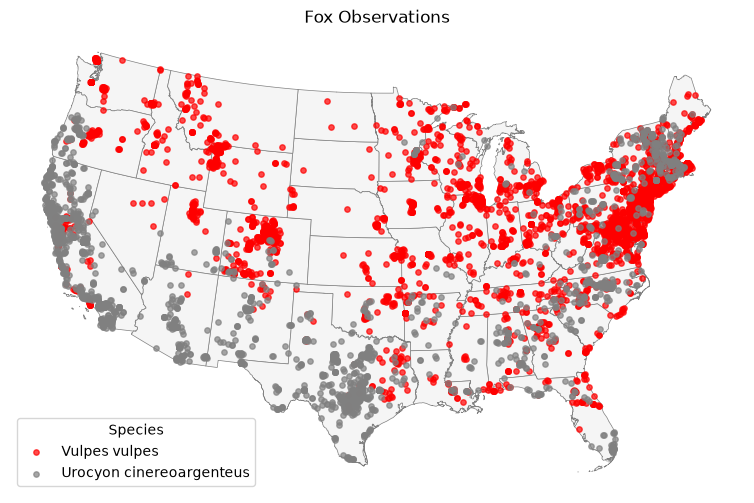

In [10]:
fig, ax = plt.subplots(figsize=(12, 6)) 
ax =  pointMap(ax)
plt.show()

In [12]:
counts = (
    points_by_state
    .groupby(["NAME", "queried_species"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Vulpes vulpes", "Urocyon cinereoargenteus"], fill_value=0)
)

counts.head()

queried_species,Vulpes vulpes,Urocyon cinereoargenteus
NAME,,
Alabama,40,47
Arizona,2,151
Arkansas,43,18
California,104,1529
Colorado,326,22


In [13]:
def barPlot(ax, counts):
    counts = counts.loc[
        counts.sum(axis=1).sort_values(ascending=False).index
    ]

    counts[["Vulpes vulpes", "Urocyon cinereoargenteus"]].plot.bar(
        ax=ax,
        stacked=True,
        color=["firebrick", "gray"]
    )

    ax.set_xlabel("State")
    ax.set_ylabel("Number of observation records")
    ax.set_title("Red and gray fox observations by state")
    ax.legend(["Red fox", "Gray fox"])
    ax.tick_params(axis="x", labelrotation=90)

    return ax

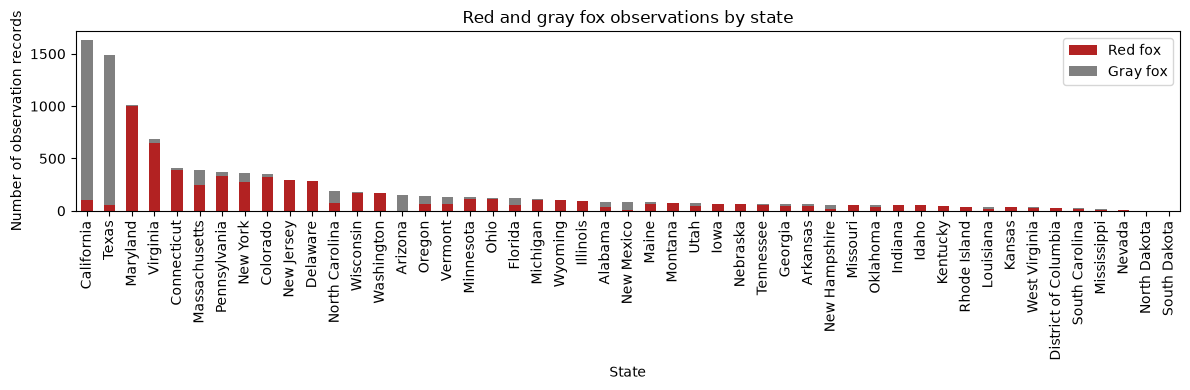

In [14]:
fig, ax = plt.subplots(figsize=(12, 4)) 
ax = barPlot(ax,counts)
fig.tight_layout()
plt.show()

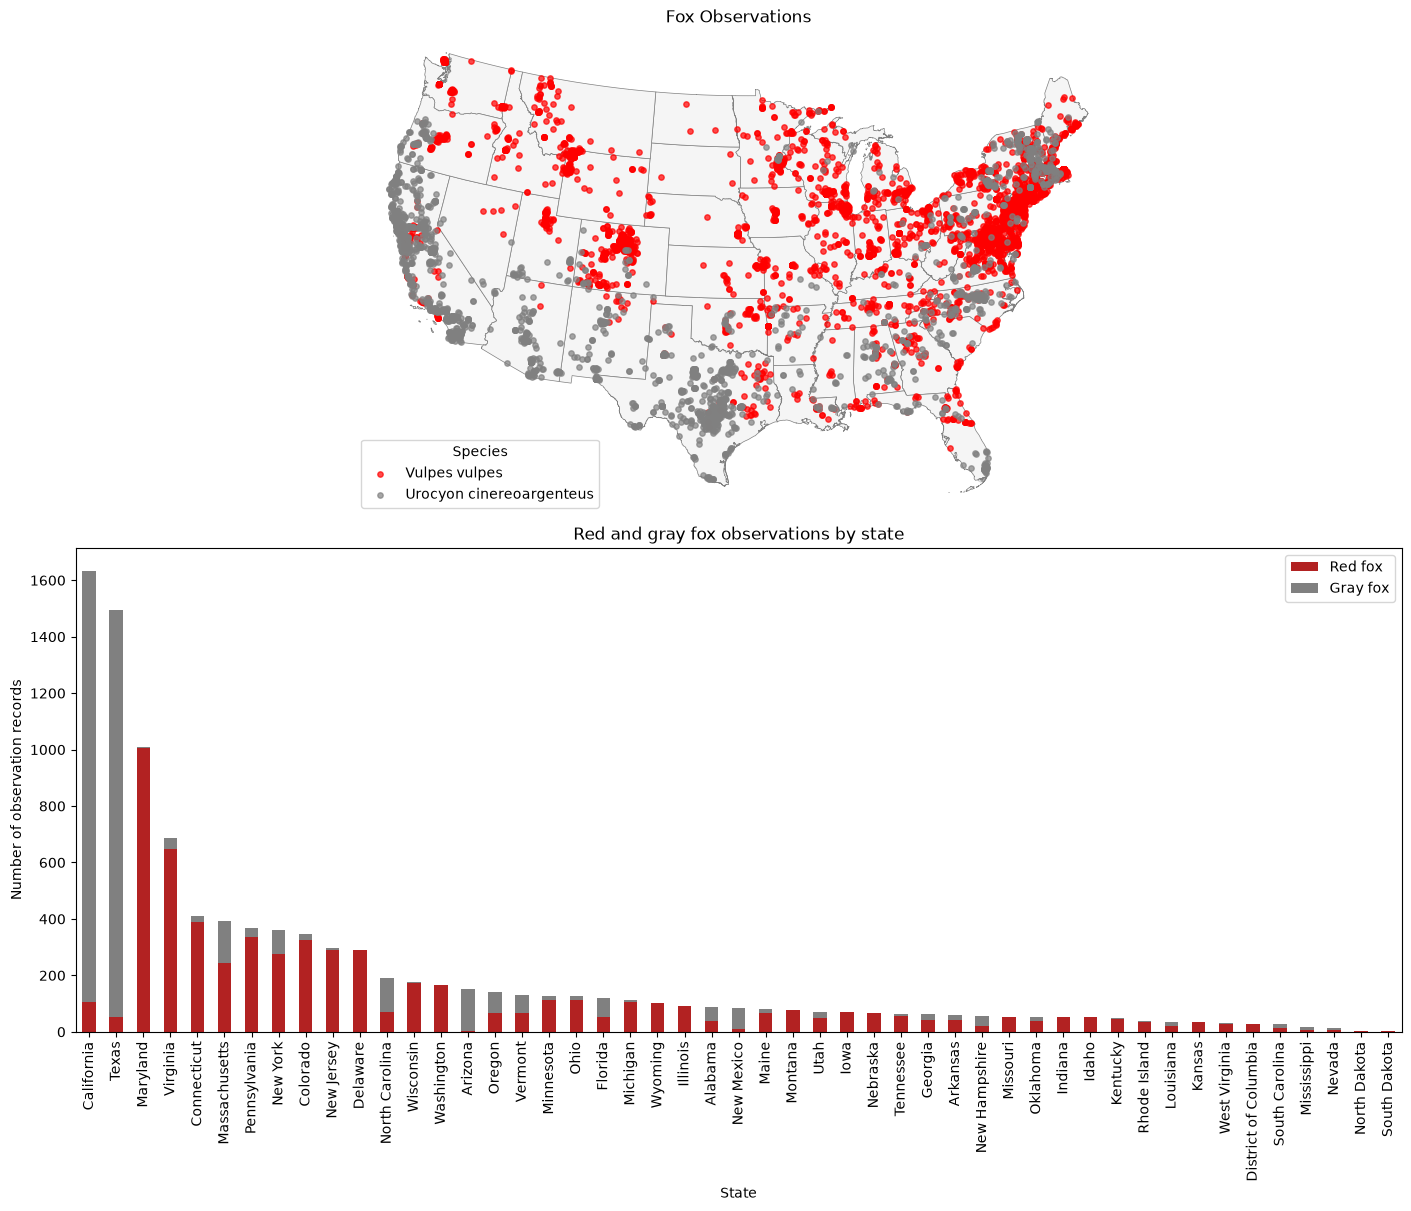

In [15]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 12),
    layout="constrained"
)

pointMap(axes[0])
barPlot(axes[1], counts)

plt.show()

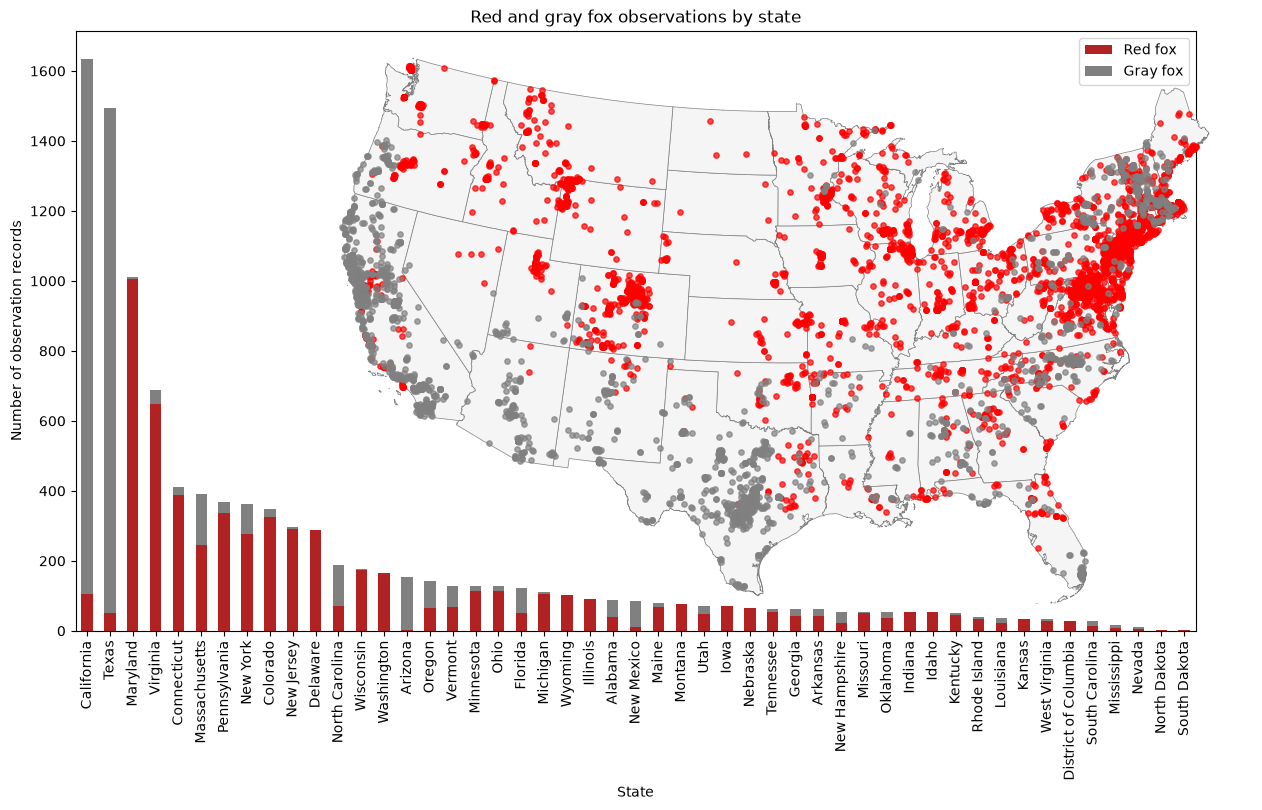

In [16]:
fig = plt.figure(figsize=(14, 8))

# [left, bottom, width, height], as fractions of the figure.
position_bar = [0.1, 0.15, 0.8, 0.75]
position_map= [0.20, 0.15, 0.8, 0.75]

ax_bar = fig.add_axes(position_bar, zorder=1)
barPlot(ax_bar, counts)

ax_map = fig.add_axes(position_map, zorder=2)
pointMap(ax_map)  # Match your function's arguments.

legend = ax_map.get_legend() # removing the legend
if legend is not None:
    legend.remove()

ax_map.set_title("") # removing the title 

# Make the upper layer transparent.
ax_map.set_facecolor("none")
ax_map.patch.set_alpha(0)
ax_map.set_axis_off()

plt.show()

In [20]:
# Made with AI

def choroplethMap(ax, contiguous_us, counts):
    # Total observations per state.
    totals = counts.sum(axis=1).rename("total")

    # Join totals to the state polygons.
    state_map = contiguous_us.merge(
        totals,
        left_on="NAME",
        right_index=True,
        how="left"
    )

    # States without records receive zero.
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        cmap="YlOrRd", # This color was selected by me not Ai 
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"label": "Number of observation records"},
        ax=ax
    )

    ax.set_title("Fox observations by state")
    ax.set_axis_off()

    return ax

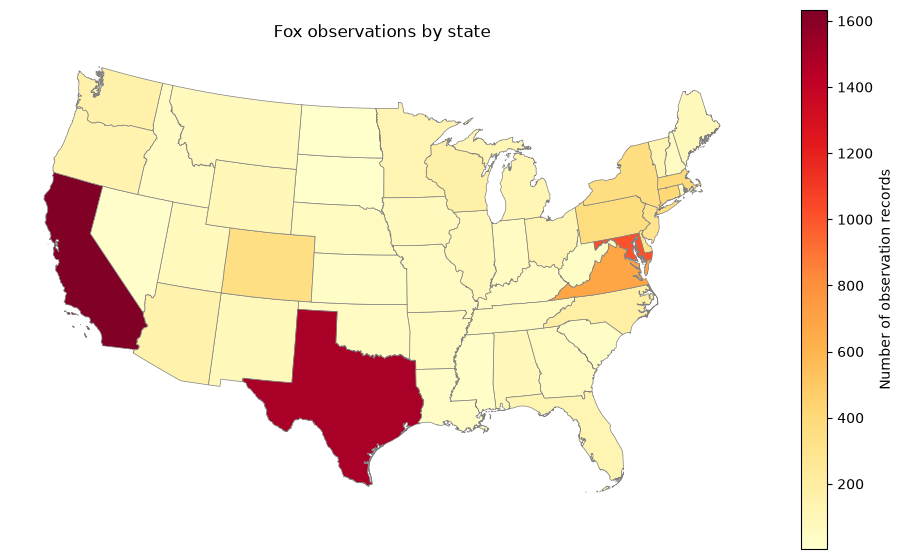

In [21]:
fig, ax = plt.subplots(figsize=(12, 7))

choroplethMap(ax, contiguous_us, counts)

plt.show()

# Choropleths

In [33]:
## code that I generated with AI to make the three different classification schemes

def choroplethEqual(ax, contiguous_us, counts):
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="equalinterval",
        k=5,
        cmap="YlOrRd",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Equal interval")
    ax.set_axis_off()
    return ax

def choroplethQuantiles(ax, contiguous_us, counts):
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="quantiles",
        k=5,
        cmap="YlOrRd",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Quantiles")
    ax.set_axis_off()
    return ax

def choroplethNatural(ax, contiguous_us, counts):
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="fisherjenks",
        k=5,
        cmap="YlOrRd",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Natural breaks (Fisher–Jenks)")
    ax.set_axis_off()
    return ax

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/geopandas/plotting.py:746: UserWarning: Numba not installed. Using slow pure python version.
  binning = mapclassify.classify(


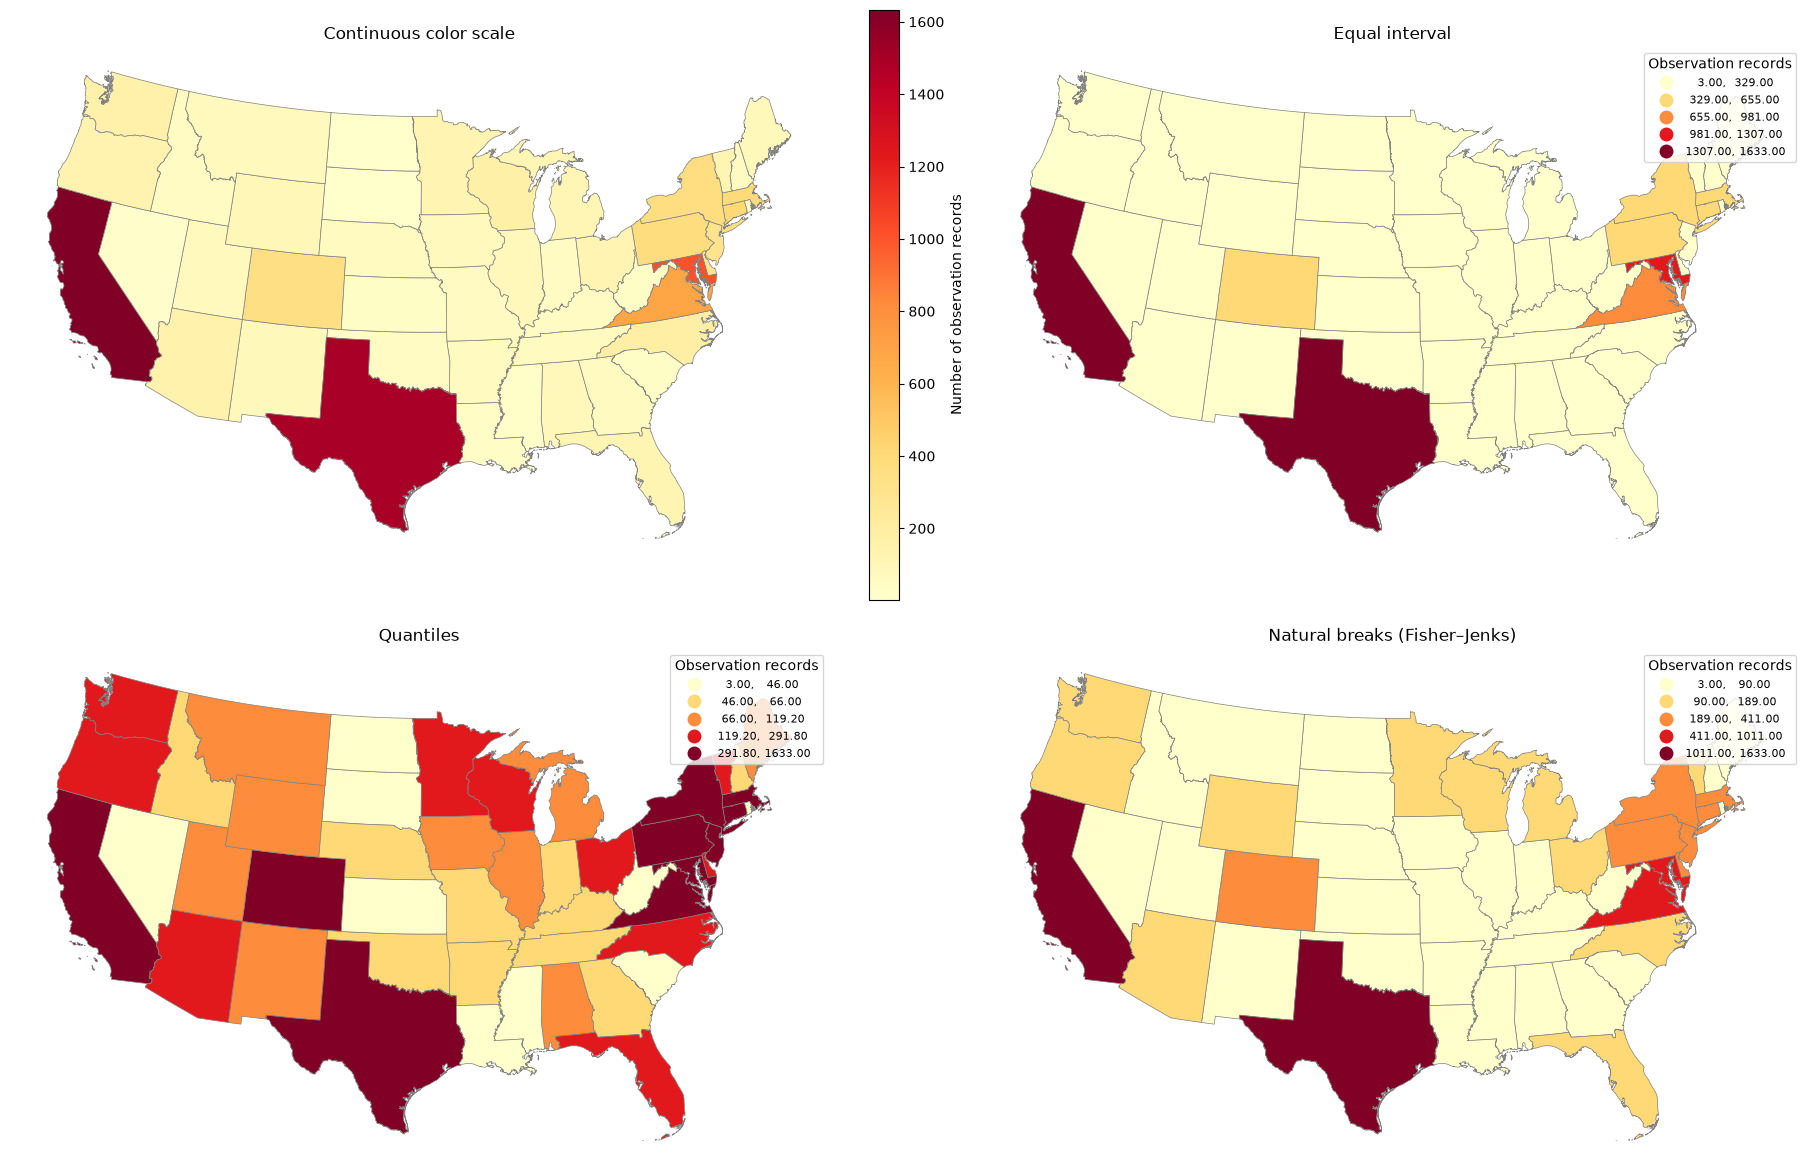

In [34]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 12),
    layout="constrained"
)

choroplethMap(axes[0, 0], contiguous_us, counts)
axes[0, 0].set_title("Continuous color scale")

choroplethEqual(axes[0, 1], contiguous_us, counts)
choroplethQuantiles(axes[1, 0], contiguous_us, counts)
choroplethNatural(axes[1, 1], contiguous_us, counts)

plt.show()

In [35]:
# Export the figure as png
fig.savefig("fox_classification.png", dpi=300, bbox_inches="tight")
plt.show()

Vulpes vulpes positive-count median: 55.0
Urocyon cinereoargenteus positive-count median: 18.5


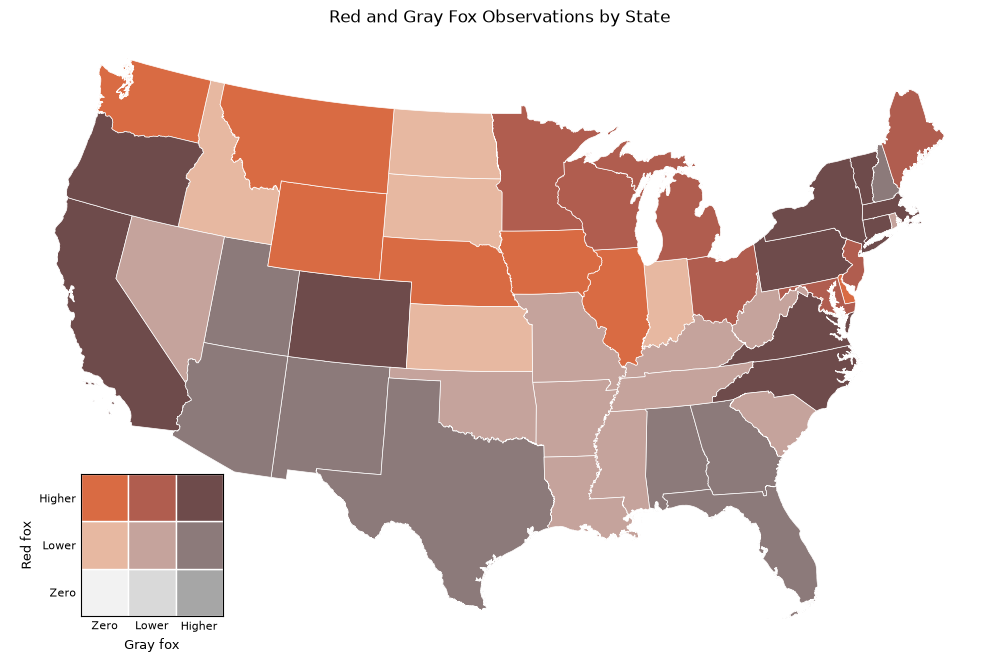

In [36]:
## Bivariate plot code generated using AI

import numpy as np
from matplotlib.patches import Rectangle

# Attach each species' counts to the state polygons
bivariate = contiguous_us.merge(
    counts,
    left_on="NAME",
    right_index=True,
    how="left"
)

species = ["Vulpes vulpes", "Urocyon cinereoargenteus"]
bivariate[species] = bivariate[species].fillna(0)

# Classify each species:
# 0 = no records
# 1 = positive count at or below the positive-count median
# 2 = count above that median
for name in species:
    values = bivariate[name]
    median = values.loc[values > 0].median()

    bivariate[name + "_class"] = np.select(
        [values == 0, values <= median],
        [0, 1],
        default=2
    )

    print(name, "positive-count median:", median)

# rows = Red fox class
# columns = Gray fox class
palette = np.array([
    ["#f2f2f2", "#d9d9d9", "#a6a6a6"],
    ["#e7b8a1", "#c5a39c", "#8c7a7a"],
    ["#d96b43", "#b05d4f", "#6e4b4b"]
])

bivariate["color"] = [
    palette[red_fox, gray_fox]
    for red_fox, gray_fox in zip(
        bivariate["Vulpes vulpes_class"],
        bivariate["Urocyon cinereoargenteus_class"]
    )
]

fig, ax = plt.subplots(figsize=(13, 8))

bivariate.plot(
    color=bivariate["color"],
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

ax.set_title("Red and Gray Fox Observations by State")
ax.set_axis_off()

# Add a 3 × 3 bivariate legend
legend_ax = ax.inset_axes([0.05, 0.05, 0.19, 0.23])

for red_fox in range(3):
    for gray_fox in range(3):
        legend_ax.add_patch(
            Rectangle(
                (gray_fox, red_fox), 1, 1,
                facecolor=palette[red_fox, gray_fox],
                edgecolor="white"
            )
        )

legend_ax.set_xlim(0, 3)
legend_ax.set_ylim(0, 3)
legend_ax.set_aspect("equal")

legend_ax.set_xticks([0.5, 1.5, 2.5])
legend_ax.set_yticks([0.5, 1.5, 2.5])
legend_ax.set_xticklabels(["Zero", "Lower", "Higher"], fontsize=8)
legend_ax.set_yticklabels(["Zero", "Lower", "Higher"], fontsize=8)

legend_ax.set_xlabel("Gray fox", fontsize=9)
legend_ax.set_ylabel("Red fox", fontsize=9)
legend_ax.tick_params(length=0)

plt.show()

In [37]:
# Export the figure as png
fig.savefig("fox_bivariate.png", dpi=300, bbox_inches="tight")
plt.show()

## AI Usage
**General Error Help**\
Had some errors due to uninstalled packages and needed program updates, so AI helped clarify which needed to be installed and how to update my general Python system.

**Color Selection**\
The class example code used red and purple colors which I did not think depicted the gray and red foxes very well, so I used AI to help select the colors in the bivariate maps that work work better for those species. 